# Проект 2. Воронка, когорты и retention интернет-магазина

**Бизнес-вопрос:** где магазин теряет пользователей на пути к покупке, на чём держится выручка и как возвращаются недельные когорты?

**Данные:** [REES46 eCommerce behavior data](https://www.kaggle.com/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store) (Kaggle), файл `2019-Oct.csv`, октябрь 2019. События: `view`, `cart`, `purchase`. Валюта в описании датасета не указана, поэтому выручка считается в единицах цены из данных.

**Как запустить:** скачать `2019-Oct.csv` с Kaggle в папку проекта, установить зависимости (`pip install -r requirements.txt`), выполнить ноутбук сверху вниз. Все SQL-запросы лежат в папке `sql/` и подгружаются из неё: ноутбук отвечает за расчёты и графики, логика метрик читается в `.sql`-файлах.

**Ключевые определения (используются во всём ноутбуке)**
- **Конверсия view → purchase** = пользователи, которые смотрели товары и купили не раньше первого просмотра, делённые на всех смотревших.
- **Доля покупателей среди всех пользователей** = все, кто купил, делённые на всех пользователей в данных. Это другая метрика: в числителе есть покупатели без просмотров. В этих данных они почти совпадают (разница в десятки человек), потому что почти все пользователи хоть раз смотрели товар.
- **Конверсия по сессиям** = доля сессий, где после первого просмотра была покупка.
- **Категорийная конверсия**: покупка засчитывается, только если пользователь купил в той же категории, которую смотрел, и не раньше первого просмотра этой категории. Аналогично для брендов и ценовых диапазонов.
- **Время до покупки**: время от первого просмотра (в октябре) до первой покупки, только для купивших после просмотра.
- **Недели когорт**: 7-дневные периоды от 1 октября (1–7, 8–14, 15–21, 22–28 октября). Остаток 29–31 октября (3 дня) неполный и в когортах не используется.
- **Activity retention**: доля когорты, у которой есть любое событие на неделе N.
- **Purchase rate**: доля когорты, купившей на неделе N. **Repeat buy rate**: среди купивших на неделе 0 доля купивших снова на неделе N.
- **Заказ** приравнен к сессии с покупкой (идентификатора заказа в данных нет), поэтому средний чек приблизительный.
- **Повторный покупатель**: пользователь с покупками в 2 и более разных календарных дня. Надёжного идентификатора заказа нет, поэтому это приближение: несколько заказов в один день не считаются повторными (оценка занижена).

**План:** 1. Загрузка → 2. Качество данных → 3. Очистка → 4. Проблема с корзиной → 5. Воронка (общая, категории, цена и бренд, время до покупки) → 6. Когорты → 7. Выгрузка для Power BI → 8. Итоги

In [ ]:
# !pip install duckdb pandas matplotlib   # при первом запуске
import os
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DATA_FILE = "2019-Oct.csv"
SQL_DIR = Path("sql")

# ноутбук, папка sql/ и файл данных должны лежать в одной папке
print("Рабочая папка:", Path.cwd())
if not SQL_DIR.is_dir():
    raise FileNotFoundError(f"Не найдена папка '{SQL_DIR}' в {Path.cwd()}. Распакуйте project2.zip целиком и откройте ноутбук "
                            "из распакованной папки (рядом должны лежать sql/ и 2019-Oct.csv).")
if not Path(DATA_FILE).is_file() and not Path("project2.db").is_file():
    raise FileNotFoundError(f"Не найден файл данных '{DATA_FILE}' в {Path.cwd()}. Скачайте его с Kaggle (ссылка выше) и положите рядом с ноутбуком.")

con = duckdb.connect("project2.db")
con.execute("SET TimeZone='UTC'")   # границы дней и недель считаем по UTC, как в источнике

CART_THRESHOLD = 2.0     # корзин на 100 просмотров: условная граница «низкого» и «высокого» режима записи корзины (выбрана по графику)
MIN_VIEWERS = 10_000     # минимальная аудитория категории / бренда для сравнения конверсий
LAST_FULL_WEEK = 3       # индекс последней полной 7-дневной недели (0 = 1–7 октября, 3 = 22–28 октября)
UNKNOWN = ("не указана", "не указан")   # группы без категории / бренда в сравнения не включаем

def q(name, **params):
    # читает запрос из sql/<name>.sql и возвращает DataFrame
    text = (SQL_DIR / f"{name}.sql").read_text(encoding="utf-8")
    if params: text = text.format(**params)
    return con.sql(text).df()

def run(name, **params):
    # то же для DDL (CREATE TABLE ...)
    text = (SQL_DIR / f"{name}.sql").read_text(encoding="utf-8")
    if params: text = text.format(**params)
    con.execute(text)

def n(x):  return f"{int(round(x)):,}".replace(",", " ")
def pct(x, d=1): return f"{x:.{d}f}%"
def show(text): display(Markdown(text))

def date_ranges(days):
    days = sorted(pd.to_datetime(list(days))); out = []; start = prev = None
    for d in days:
        if start is None: start = prev = d
        elif (d - prev).days == 1: prev = d
        else: out.append((start, prev)); start = prev = d
    if start is not None: out.append((start, prev))
    return ", ".join(f"{a:%d.%m}" if a == b else f"{a:%d.%m}–{b:%d.%m}" for a, b in out)

## 1. Загрузка и первый взгляд

In [2]:
con.execute(f"CREATE TABLE IF NOT EXISTS events AS SELECT * FROM read_csv_auto('{DATA_FILE}')")

raw = q("00_raw_summary").iloc[0]
types = q("00_event_types")
types["share_pct"] = types["cnt"] / types["cnt"].sum() * 100
display(types)

types_txt = ", ".join(f"{r.event_type} — {pct(r.share_pct)}" for r in types.itertuples())
show(f"**Сводка.** {n(raw.rows_cnt)} событий за {raw.first_event:%d.%m.%Y}–{raw.last_event:%d.%m.%Y}, "
     f"{n(raw.users)} пользователей. Структура событий: {types_txt}.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,cnt,share_pct
0,view,40779399,96.067341
1,cart,926516,2.182669
2,purchase,742849,1.749990


**Сводка.** 42 448 764 событий за 01.10.2019–31.10.2019, 3 022 290 пользователей. Структура событий: view — 96.1%, cart — 2.2%, purchase — 1.7%.

## 2. Проверка качества данных

In [3]:
dq = q("01_quality_checks").iloc[0]
zero_price = q("02_zero_price_by_type")

total = int(dq.rows_cnt)
zp_txt = ", ".join(f"{r.event_type} ({n(r.cnt)})" for r in zero_price.itertuples()) or "нет"
show(f'''**Сводка.**
- Пустой `category_code`: {n(dq.null_category_code)} строк ({pct(100*dq.null_category_code/total)}); пустой `brand`: {n(dq.null_brand)} ({pct(100*dq.null_brand/total)}).
- Пустой `user_session`: {n(dq.null_session)}; пустая цена: {n(dq.null_price)}.
- Цена ≤ 0: {n(dq.nonpositive_price)} ({pct(100*dq.nonpositive_price/total, 2)}), по типам событий: {zp_txt}.''')

**Сводка.**
- Пустой `category_code`: 13 515 609 строк (31.8%); пустой `brand`: 6 113 008 (14.4%).
- Пустой `user_session`: 2; пустая цена: 0.
- Цена ≤ 0: 68 673 (0.16%), по типам событий: view (68 523), cart (150).

## 3. Очистка

Что делаем и почему:
- **Строки без `user_session` удаляем**: сессия нужна для расчёта заказов и сессионной конверсии.
- **Полные дубли удаляем**: одинаковое событие не может быть записано дважды.
- **Пустые `category_code` и `brand` оставляем**: их много, удаление исказило бы воронку; для категорий и брендов они выделены в отдельную группу и в сравнения не входят.
- **Цену ≤ 0 оставляем в событиях, но исключаем из выручки**: такие значения есть только у просмотров (68 523) и корзин (150), покупок с нулевой ценой нет, поэтому на конверсию и выручку это не влияет.

In [4]:
run("03_clean")
rows_clean = int(con.sql("SELECT COUNT(*) FROM events_clean").df().iloc[0, 0])
dups = total - int(dq.null_session) - rows_clean   # полные дубли среди строк с непустой сессией

dq_summary = pd.DataFrame([
    ("Пустой category_code", int(dq.null_category_code), "оставлено, группа «не указана»"),
    ("Пустой brand",          int(dq.null_brand),         "оставлено, группа «не указан»"),
    ("Пустой user_session",   int(dq.null_session),       "удалено"),
    ("Полные дубли",          dups,                       "удалено"),
    ("Цена <= 0",             int(dq.nonpositive_price),  "оставлено; исключено из расчёта выручки"),
], columns=["check", "rows", "action"])
dq_summary["share_pct"] = (dq_summary["rows"] / total * 100).round(3)
dq_summary["rows_total_raw"] = total
dq_summary["rows_after_cleaning"] = rows_clean
display(dq_summary)

show(f"**Сводка.** Полных дублей удалено: {n(dups)} ({pct(100*dups/total, 2)}). После очистки осталось {n(rows_clean)} из {n(total)} строк "
     f"(удалено {n(total - rows_clean)}, {pct(100*(total-rows_clean)/total, 2)}). Дальше используется только `events_clean`.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,check,rows,action,share_pct,rows_total_raw,rows_after_cleaning
0,Пустой category_code,13515609,"оставлено, группа «не указана»",31.840,42448764,42418542
1,Пустой brand,6113008,"оставлено, группа «не указан»",14.401,42448764,42418542
2,Пустой user_session,2,удалено,0.000,42448764,42418542
3,Полные дубли,30220,удалено,0.071,42448764,42418542
4,Цена <= 0,68673,оставлено; исключено из расчёта выручки,0.162,42448764,42418542


**Сводка.** Полных дублей удалено: 30 220 (0.07%). После очистки осталось 42 418 542 из 42 448 764 строк (удалено 30 222, 0.07%). Дальше используется только `events_clean`.

## 4. Проблема с событием «корзина»

В нормальной воронке покупателей не больше, чем людей, добавивших товар в корзину, а покупок не больше, чем корзин. Проверяем, можно ли доверять событию `cart`: смотрим, был ли у покупателей след корзины, и как корзины ведут себя по дням.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,segment,users,share_of_buyers_pct
0,Корзина до покупки,167998,48.4
1,Корзины не было вообще,144341,41.6
2,Корзина только после покупки,34779,10.0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

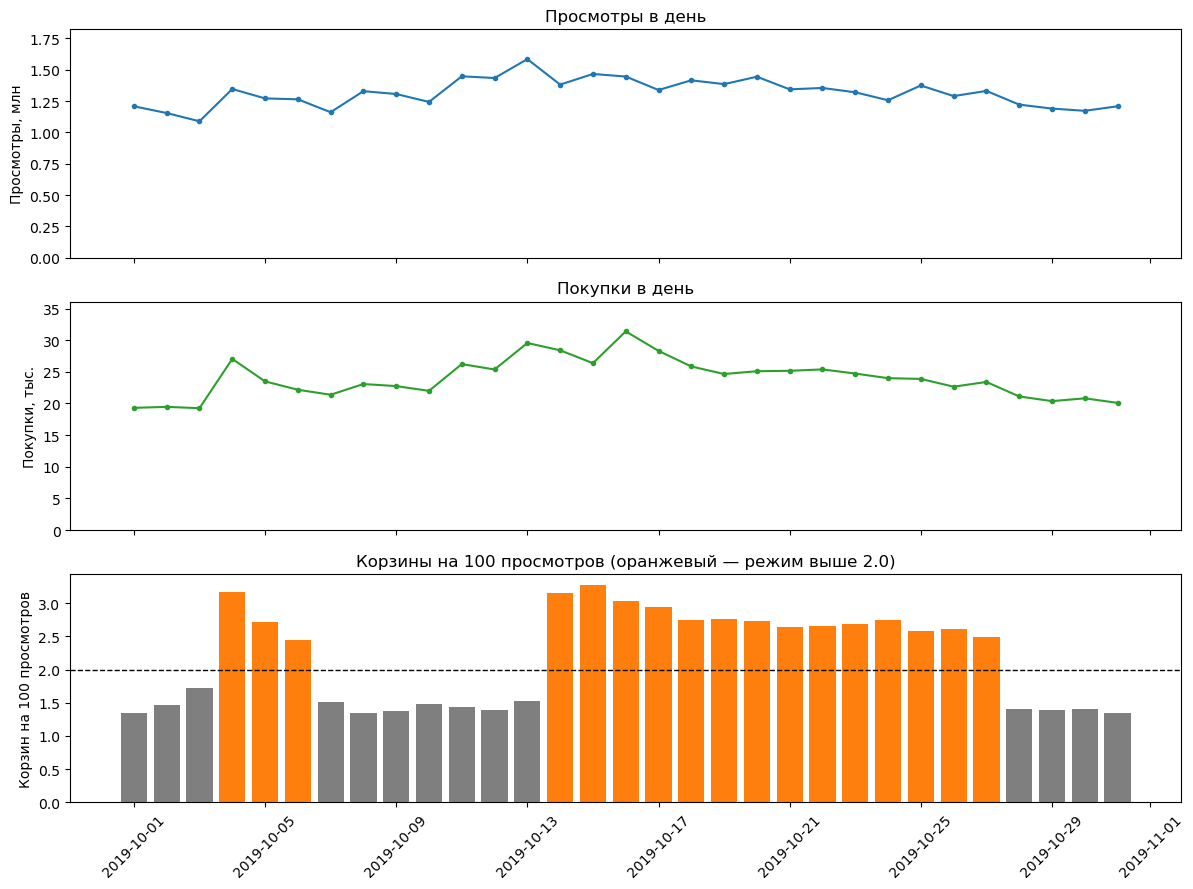

**Сводка (цифры).**
- Покупатели по сегментам: корзина до покупки — 48.4%, корзины не было вообще — 41.6%, корзина только после покупки — 10.0%. Покупателей: 347 118, добавлявших в корзину: 337 117.
- Вариативность по дням (коэффициент вариации): просмотры 8%, покупки 13%, корзины 36%.
- Корзин на 100 просмотров: от 1.34 до 3.28. Выше 2.0: 04.10–06.10, 14.10–27.10 (17 дн.); ниже: 01.10–03.10, 07.10–13.10, 28.10–31.10 (14 дн.).
- Дней, когда покупок больше, чем корзин: 14 из 31.

In [5]:
buyer_seg = q("04_cart_buyer_segments").iloc[0]

cart_buyer_segments = pd.DataFrame({
    "segment": ["Корзина до покупки", "Корзины не было вообще", "Корзина только после покупки"],
    "users": [int(buyer_seg.cart_before_purchase), int(buyer_seg.never_added_to_cart), int(buyer_seg.cart_only_after_purchase)],
})
cart_buyer_segments["share_of_buyers_pct"] = (cart_buyer_segments["users"] / int(buyer_seg.buyers) * 100).round(1)
display(cart_buyer_segments)

daily = q("05_daily_metrics")
daily["day"] = pd.to_datetime(daily["day"])
daily["carts_per_100_views"]     = 100 * daily["carts"] / daily["views"]
daily["purchases_per_100_views"] = 100 * daily["purchase_events"] / daily["views"]
daily["purchases_per_cart"]      = daily["purchase_events"] / daily["carts"]
daily["buyers_share_pct"]        = 100 * daily["buyers"] / daily["active_users"]
daily["avg_check_approx"]        = daily["revenue"] / daily["approx_orders"]
daily["cart_regime"] = (daily["carts_per_100_views"] >= CART_THRESHOLD).map({True: "high_cart", False: "low_cart"})

# три отдельные панели: у просмотров, покупок и корзин разные масштабы
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(daily["day"], daily["views"] / 1e6, marker="o", ms=3)
axes[0].set_ylabel("Просмотры, млн"); axes[0].set_ylim(0, daily["views"].max() / 1e6 * 1.15)
axes[0].set_title("Просмотры в день")
axes[1].plot(daily["day"], daily["purchase_events"] / 1e3, marker="o", ms=3, color="tab:green")
axes[1].set_ylabel("Покупки, тыс."); axes[1].set_ylim(0, daily["purchase_events"].max() / 1e3 * 1.15)
axes[1].set_title("Покупки в день")
colors = daily["cart_regime"].map({"high_cart": "tab:orange", "low_cart": "tab:gray"})
axes[2].bar(daily["day"], daily["carts_per_100_views"], color=colors)
axes[2].axhline(CART_THRESHOLD, ls="--", color="black", lw=1)
axes[2].set_ylabel("Корзин на 100 просмотров")
axes[2].set_title(f"Корзины на 100 просмотров (оранжевый — режим выше {CART_THRESHOLD})")
for a in axes: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

cv = lambda s: s.std() / s.mean() * 100
hi_days = daily.loc[daily.cart_regime == "high_cart", "day"]
lo_days = daily.loc[daily.cart_regime == "low_cart", "day"]
days_more_purchases = int((daily["purchase_events"] > daily["carts"]).sum())
cv_v, cv_p, cv_c = cv(daily["views"]), cv(daily["purchase_events"]), cv(daily["carts"])

show(f'''**Сводка (цифры).**
- Покупатели по сегментам: корзина до покупки — {pct(cart_buyer_segments.share_of_buyers_pct[0])}, корзины не было вообще — {pct(cart_buyer_segments.share_of_buyers_pct[1])}, корзина только после покупки — {pct(cart_buyer_segments.share_of_buyers_pct[2])}. Покупателей: {n(buyer_seg.buyers)}, добавлявших в корзину: {n(buyer_seg.carters)}.
- Вариативность по дням (коэффициент вариации): просмотры {pct(cv_v,0)}, покупки {pct(cv_p,0)}, корзины {pct(cv_c,0)}.
- Корзин на 100 просмотров: от {daily.carts_per_100_views.min():.2f} до {daily.carts_per_100_views.max():.2f}. Выше {CART_THRESHOLD}: {date_ranges(hi_days) or "нет дней"} ({len(hi_days)} дн.); ниже: {date_ranges(lo_days) or "нет дней"} ({len(lo_days)} дн.).
- Дней, когда покупок больше, чем корзин: {days_more_purchases} из {len(daily)}.''')

### Проверка: когда покупатели оказываются без корзины

Если люди клали товары в корзину до 1 октября (данных за сентябрь нет), доля покупателей без корзины была бы высокой в начале месяца и плавно снижалась. Если же менялась запись корзины в системе, доля будет меняться скачками на границах режимов.

Оговорки: день считается по **первой** покупке пользователя; «без корзины» включает и тех, у кого корзина появилась только после покупки; режимы определены по числу корзин на 100 просмотров, поэтому проверка не является независимым доказательством, но показывает, что скачки есть именно у покупателей.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

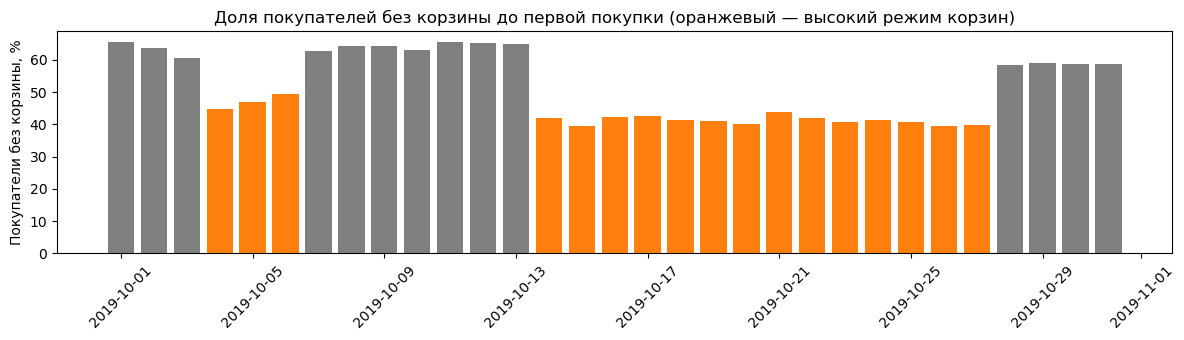

,days,buyers,no_cart,no_cart_pct
cart_regime,,,,
high_cart,17,191749,81310,42.4
low_cart,14,155369,97810,63.0


**Сводка.** Без корзины перед первой покупкой: 42.4% покупателей в «высокие» дни и 63.0% в «низкие».

In [6]:
nc = q("15_buyers_without_cart_by_day")
nc["day"] = pd.to_datetime(nc["day"])
nc["no_cart_pct"] = (100 * nc["buyers_no_cart_before"] / nc["buyers"]).round(1)
nc = nc.merge(daily[["day", "cart_regime"]], on="day", how="left")

fig, ax = plt.subplots(figsize=(12, 3.5))
colors = nc["cart_regime"].map({"high_cart": "tab:orange", "low_cart": "tab:gray"})
ax.bar(nc["day"], nc["no_cart_pct"], color=colors)
ax.set_ylabel("Покупатели без корзины, %")
ax.set_title("Доля покупателей без корзины до первой покупки (оранжевый — высокий режим корзин)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

by_regime = nc.groupby("cart_regime").agg(days=("day", "count"),
                                          buyers=("buyers", "sum"),
                                          no_cart=("buyers_no_cart_before", "sum"))
by_regime["no_cart_pct"] = (100 * by_regime["no_cart"] / by_regime["buyers"]).round(1)
display(by_regime)

rg = by_regime["no_cart_pct"].to_dict()
show(f'''**Сводка.** Без корзины перед первой покупкой: {rg.get("high_cart", "н/д")}% покупателей в «высокие» дни и {rg.get("low_cart", "н/д")}% в «низкие».''')

**Вывод по корзине.** Событию `cart` в этих данных доверять нельзя: у 41.6% покупателей корзины не было вообще, у 10% она появилась только после покупки, число корзин на 100 просмотров скачет в 2.4 раза (1.34–3.28, коэффициент вариации 36% против 8% у просмотров и 13% у покупок), а в 14 днях из 31 покупок больше, чем корзин. Поэтому шаг `cart` **исключён** из основной воронки и из KPI.

**Что показывает дополнительная проверка.** Доля покупателей без корзины перед первой покупкой меняется скачкообразно на границах режимов: около 42% в «высокие» дни и 63% в «низкие» (границы 4, 7, 14 и 28 октября). Постепенного снижения в начале месяца нет, поэтому гипотеза о корзинах, собранных в сентябре, не подтверждается. Резкие синхронные скачки больше похожи на изменение системы (запись корзины или интерфейс), чем на изменение поведения пользователей; по данным отличить одно от другого нельзя. Даже в «хорошие» дни около 40% покупателей без корзины: покупка в один клик или постоянный недоучёт, по данным не установить.

Порог 2.0 выбран по виду графика: границы режимов на нём хорошо видны, но сам порог произвольный.

## 5. Воронка просмотр → покупка

### 5.1 Общая воронка

Считаем две метрики, чтобы их не путать: конверсию среди смотревших и долю покупателей среди всех пользователей. Шаг «все пользователи → смотрели» в воронку не выносим: почти все пользователи смотрели товары, и этот шаг ничего не показывает. Воронка поэтому двухшаговая (просмотр → покупка), а детализация идёт через категории, цену, бренд и время до покупки.

In [7]:
users_f = q("06_funnel_users").iloc[0]
sess_f  = q("07_funnel_sessions").iloc[0]
money   = q("08_money").iloc[0]
rep     = q("09_repeat_buyers").iloc[0]

all_users, viewers = int(users_f.all_users), int(users_f.viewers)
viewer_buyers, buyers_all = int(users_f.viewer_buyers), int(users_f.buyers_all)
conv_view_purchase = 100 * viewer_buyers / viewers
buyers_share_all   = 100 * buyers_all / all_users
session_conv       = 100 * sess_f.sessions_view_purchase / sess_f.sessions_with_view
repeat_pct         = 100 * rep.repeat_buyers / rep.buyers
revenue            = float(money.revenue)
avg_check_approx   = revenue / money.approx_orders
revenue_per_buyer  = revenue / buyers_all

funnel_overall = pd.DataFrame({
    "step_order": [1, 2],
    "step": ["Смотрели товары", "Купили после просмотра"],
    "users": [viewers, viewer_buyers],
})
funnel_overall["pct_of_viewers"] = (funnel_overall["users"] / viewers * 100).round(2)
display(funnel_overall)

show(f'''**Сводка по магазину.**
- Конверсия **view → purchase**: {pct(conv_view_purchase, 2)} ({n(viewer_buyers)} купивших после просмотра из {n(viewers)} смотревших).
- Доля покупателей **среди всех пользователей**: {pct(buyers_share_all, 2)} ({n(buyers_all)} из {n(all_users)}); покупателей без просмотров в данных: {n(users_f.buyers_without_view)}.
- Конверсия по сессиям: {pct(session_conv, 2)}.
- Выручка: {n(revenue)}; на одного покупателя: {revenue_per_buyer:,.0f}; примерный средний чек (выручка / сессии с покупкой): {avg_check_approx:,.0f}.
- Покупали в 2 и более разных дня: {pct(repeat_pct)} покупателей.''')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,step_order,step,users,pct_of_viewers
0,1,Смотрели товары,3022130,100.00
1,2,Купили после просмотра,346950,11.48


**Сводка по магазину.**
- Конверсия **view → purchase**: 11.48% (346 950 купивших после просмотра из 3 022 130 смотревших).
- Доля покупателей **среди всех пользователей**: 11.49% (347 118 из 3 022 290); покупателей без просмотров в данных: 62.
- Конверсия по сессиям: 6.79%.
- Выручка: 229 933 213; на одного покупателя: 662; примерный средний чек (выручка / сессии с покупкой): 365.
- Покупали в 2 и более разных дня: 26.1% покупателей.

Конверсия по пользователям за месяц выше сессионной, потому что у пользователя за месяц много сессий, в которых он может купить; сравнивать эти два числа как «хорошо/плохо» нельзя, это разные единицы наблюдения.

### 5.2 Воронка по категориям (покупка в той же категории, что и просмотр)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,category,viewers,viewer_buyers,buyers_all,buyers_without_category_view,revenue,conv_pct,share_of_viewers_pct,revenue_share_pct
0,electronics,1683322,199865,200031,74,1.764456e+08,11.87,55.70,76.74
1,не указана,1514526,104862,104897,14,2.292217e+07,6.92,50.11,9.97
2,appliances,544299,49254,49280,11,1.358176e+07,9.05,18.01,5.91
3,apparel,259014,5186,5186,0,6.249378e+05,2.00,8.57,0.27
4,computers,248605,16189,16200,6,1.137787e+07,6.51,8.23,4.95
5,furniture,202651,5641,5644,1,1.673243e+06,2.78,6.71,0.73
6,auto,159144,7377,7382,1,1.273956e+06,4.64,5.27,0.55
7,construction,101834,5348,5353,4,9.329950e+05,5.25,3.37,0.41
8,kids,100074,3687,3689,1,6.781407e+05,3.68,3.31,0.29
9,accessories,50753,1134,1134,0,6.878388e+04,2.23,1.68,0.03


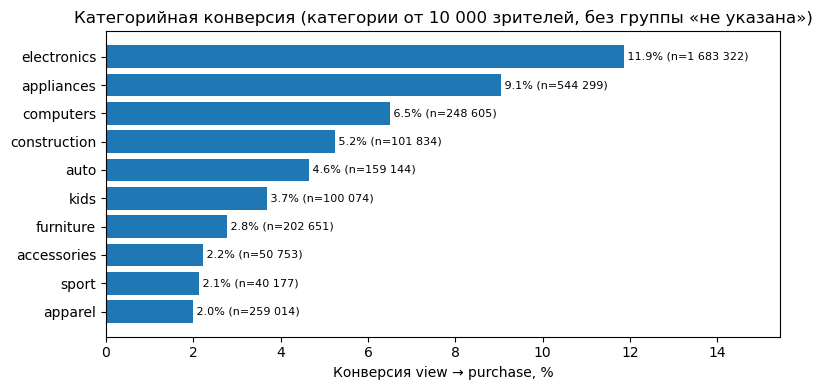

**Сводка по категориям.**
- Категорий с аудиторией от 10 000 (без «не указана»): 10.
- Самая высокая конверсия: electronics (11.9%, 1 683 322 зрителей), appliances (9.1%, 544 299 зрителей), computers (6.5%, 248 605 зрителей).
- Самая низкая конверсия: apparel (2.0%, 259 014 зрителей), sport (2.1%, 40 177 зрителей), accessories (2.2%, 50 753 зрителей).
- Больше всего выручки: electronics — 76.7% от всей выручки.
- Пользователь, смотревший несколько категорий, учитывается в каждой, поэтому сумма зрителей по категориям больше общего числа смотревших. Группа «не указана»: 50.1% зрителей, конверсия 6.9%; в рейтинг не включена, потому что это не категория, а пропуск в данных.

In [8]:
cat = q("10_funnel_category")
cat["conv_pct"] = (100 * cat["viewer_buyers"] / cat["viewers"]).where(cat["viewers"] > 0).round(2)
cat["share_of_viewers_pct"] = (100 * cat["viewers"] / viewers).round(2)
cat["revenue"] = cat["revenue"].fillna(0).round(2)
cat["revenue_share_pct"] = (100 * cat["revenue"] / cat["revenue"].sum()).round(2)
cat = cat.sort_values("viewers", ascending=False).reset_index(drop=True)
display(cat)

named = cat[~cat["category"].isin(UNKNOWN)]
big = named[named["viewers"] >= MIN_VIEWERS].sort_values("conv_pct")
if big.empty:                      # на малых выборках порог может отсечь всё
    big = named.dropna(subset=["conv_pct"]).sort_values("conv_pct")

fig, ax = plt.subplots(figsize=(8, max(3, 0.4 * len(big))))
ax.barh(big["category"], big["conv_pct"])
for i, (v, vw) in enumerate(zip(big["conv_pct"], big["viewers"])):
    ax.text(v, i, f" {v:.1f}% (n={n(vw)})", va="center", fontsize=8)
ax.set_xlim(0, big["conv_pct"].max() * 1.3)
ax.set_xlabel("Конверсия view → purchase, %")
ax.set_title(f"Категорийная конверсия (категории от {n(MIN_VIEWERS)} зрителей, без группы «не указана»)")
plt.tight_layout(); plt.show()

top3 = big.sort_values("conv_pct", ascending=False).head(3)
bot3 = big.sort_values("conv_pct").head(3)
fmt = lambda df: ", ".join(f"{r.category} ({pct(r.conv_pct)}, {n(r.viewers)} зрителей)" for r in df.itertuples())
top_rev = cat.sort_values("revenue", ascending=False).iloc[0]
nocat = cat[cat["category"].isin(UNKNOWN)]
nocat_txt = (f" Группа «не указана»: {pct(nocat.share_of_viewers_pct.iloc[0])} зрителей, конверсия {pct(nocat.conv_pct.iloc[0])}; в рейтинг не включена, потому что это не категория, а пропуск в данных."
             if len(nocat) else "")

show(f'''**Сводка по категориям.**
- Категорий с аудиторией от {n(MIN_VIEWERS)} (без «не указана»): {len(big)}.
- Самая высокая конверсия: {fmt(top3)}.
- Самая низкая конверсия: {fmt(bot3)}.
- Больше всего выручки: {top_rev.category} — {pct(top_rev.revenue_share_pct)} от всей выручки.
- Пользователь, смотревший несколько категорий, учитывается в каждой, поэтому сумма зрителей по категориям больше общего числа смотревших.{nocat_txt}''')

### 5.3 Конверсия по цене и бренду

Проверяем, объясняется ли низкая конверсия в отдельных категориях ценой или брендом, а не «категорией вообще».

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,price_band,viewers,viewer_buyers,revenue,conv_pct
0,1: до 50,1175579,76395,3.446725e+06,6.50
1,2: 50–100,1111325,63816,6.724149e+06,5.74
2,3: 100–250,1694288,142573,4.173161e+07,8.41
3,4: 250–500,1310573,84882,5.081292e+07,6.48
4,5: от 500,1156112,65140,1.271808e+08,5.63


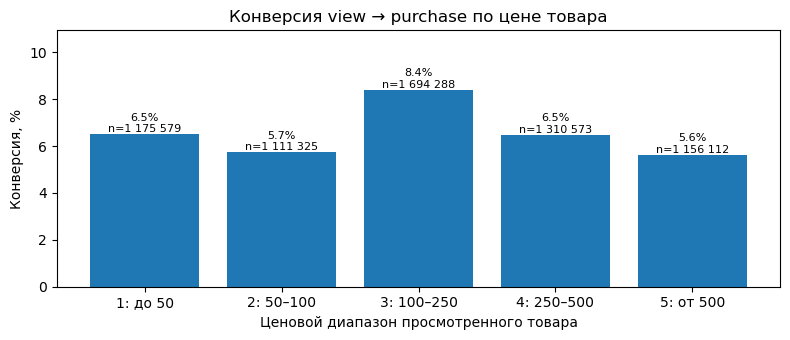

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Бренды от 10 000 зрителей: 167. Топ-10 по конверсии:


,brand,viewers,viewer_buyers,revenue,conv_pct
1700,samsung,935464,93946,4.638738e+07,10.04
2580,apple,729319,65543,1.111850e+08,8.99
1930,omron,14722,1200,8.410664e+04,8.15
2802,xiaomi,470832,35041,9.191141e+06,7.44
1488,triangle,61627,4443,2.884564e+05,7.21
4,ariston,16573,1163,1.922332e+05,7.02
2358,huawei,234061,15360,4.881654e+06,6.56
2141,cordiant,119818,7721,5.176054e+05,6.44
3014,epson,13990,886,3.019767e+05,6.33
1924,nokian,55228,3484,3.729976e+05,6.31


10 самых низких по конверсии:


,brand,viewers,viewer_buyers,revenue,conv_pct
2370,silverlit,15295,31,2202.87,0.20
3049,jordan,14528,42,7714.90,0.29
264,intex,11919,35,2691.97,0.29
1275,gerat,15376,65,3424.39,0.42
29,omabelle,46050,205,347730.87,0.45
624,milavitsa,15611,70,1947.97,0.45
1706,nike,49069,227,29802.23,0.46
217,smeg,12070,63,40448.65,0.52
1076,puma,10718,66,7142.37,0.62
224,greyder,13975,88,11337.37,0.63


In [9]:
pb = q("11_funnel_price_band")
pb["conv_pct"] = (100 * pb["viewer_buyers"] / pb["viewers"]).round(2)
pb["revenue"] = pb["revenue"].fillna(0).round(2)
display(pb)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(pb["price_band"], pb["conv_pct"])
for i, (v, vw) in enumerate(zip(pb["conv_pct"], pb["viewers"])):
    ax.text(i, v, f"{v:.1f}%\nn={n(vw)}", ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, pb["conv_pct"].max() * 1.3)
ax.set_ylabel("Конверсия, %"); ax.set_xlabel("Ценовой диапазон просмотренного товара")
ax.set_title("Конверсия view → purchase по цене товара")
plt.tight_layout(); plt.show()

brand = q("12_funnel_brand")
brand["conv_pct"] = (100 * brand["viewer_buyers"] / brand["viewers"]).round(2)
brand["revenue"] = brand["revenue"].fillna(0).round(2)
brand_named = brand[~brand["brand"].isin(UNKNOWN)]
brand_big = brand_named[brand_named["viewers"] >= MIN_VIEWERS].sort_values("conv_pct", ascending=False)
if brand_big.empty:
    brand_big = brand_named.sort_values("viewers", ascending=False).head(20).sort_values("conv_pct", ascending=False)

print(f"Бренды от {n(MIN_VIEWERS)} зрителей: {len(brand_big)}. Топ-10 по конверсии:")
display(brand_big.head(10))
print("10 самых низких по конверсии:")
display(brand_big.tail(10).sort_values("conv_pct"))

**Интерпретация 5.3.**
- **Цена.** Конверсия по диапазонам различается умеренно: от 5.6% (от 500) до 8.4% (100–250), закономерности «дороже — хуже» нет. По выручке картина другая: диапазон от 500 даёт около 55%, 250–500 около 22%, 100–250 около 18%, всё дешевле 100 менее 5%.
- **Apparel.** Конверсия apparel (2.0%) ниже, чем в любом ценовом диапазоне (минимум 5.6%), поэтому одной ценой её, по-видимому, не объяснить. Прямая проверка (категория × цена) не делалась.
- **Бренды.** Выше всех конвертируют бренды электроники: samsung (10.0%), apple (9.0%), xiaomi (7.4%). Среди самых низких (0.2–0.6%) по названиям преобладают одежда и обувь (nike, puma, jordan, milavitsa, greyder); категории этих брендов по данным не проверялись, поэтому это гипотеза.
- **Концентрация выручки.** На apple приходится около 48% выручки, на samsung около 20%: два бренда дают около 68%.
- **Вывод.** Низкая конверсия одежды выглядит устойчивой особенностью категории и её брендов, а не проблемой отдельных цен. Зависимость выручки от двух брендов — отдельный риск.

### 5.4 Сколько времени проходит от первого просмотра до покупки

Показывает, нужно ли возвращать пользователя в тот же день или покупки откладываются на дни.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,time_to_purchase,buyers,share_pct
0,1: до 1 часа,165549,47.7
1,2: 1–24 часа,33881,9.8
2,3: 1–7 дней,65737,19.0
3,4: больше 7 дней,81589,23.5


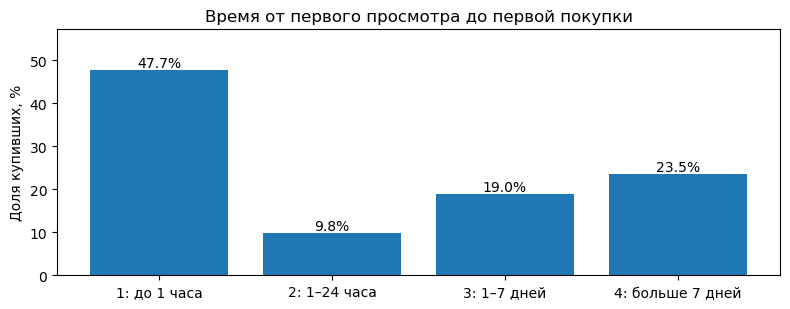

In [10]:
ttp = q("13_time_to_purchase")
ttp["share_pct"] = (100 * ttp["buyers"] / ttp["buyers"].sum()).round(1)
display(ttp)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(ttp["time_to_purchase"], ttp["share_pct"])
for i, v in enumerate(ttp["share_pct"]): ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
ax.set_ylim(0, ttp["share_pct"].max() * 1.2)
ax.set_ylabel("Доля купивших, %"); ax.set_title("Время от первого просмотра до первой покупки")
plt.tight_layout(); plt.show()

**Интерпретация 5.4.** Среди купивших после просмотра 47.7% совершают первую покупку в течение часа после первого просмотра, ещё 9.8% в течение суток (всего 57.5%). Через 1–7 дней покупают 19.0%, позже 7 дней — 23.5%. Около половины покупок происходит почти сразу, но заметная доля (около четверти) откладывается больше чем на неделю.

Оговорки: «первый просмотр» здесь первый в октябре, а не вообще, поэтому у давних пользователей реальное время размышления больше; у пришедших в конце месяца окно наблюдения короче, поэтому доля «долго» занижена.

## 6. Когорты и retention

**Определения.**
- Когорта: 7-дневная неделя (от 1 октября), в которой пользователь впервые появился в данных.
- Используются только полные недели 1–28 октября. 29–31 октября (3 дня) исключены, чтобы неполная неделя не занижала retention.
- **Когорта 1–7 октября смешанная** (отмечена `*`): в ней и новые, и давние пользователи, потому что данных за сентябрь нет. Давние пользователи заходят чаще, поэтому у этой когорты retention, скорее всего, выше.
- Следующие когорты тоже неидеальны: туда попадает и тот, кто пользовался магазином раньше, но просто не заходил в предыдущие недели октября.
- **Поэтому когорты между собой сравнивать нельзя**: разница в retention может быть вызвана составом когорты, а не качеством удержания. Ниже показываем сами значения, но тренд между когортами не интерпретируем.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Размеры когорт (* — смешанная когорта):


,cohort_size
cohort_label,
01.10–07.10*,957543
08.10–14.10,731325
15.10–21.10,623332
22.10–28.10,522809


Activity retention, %


week_n,0,1,2,3
cohort_label,,,,
01.10–07.10*,100.0,34.74,31.02,26.67
08.10–14.10,100.0,26.79,21.42,NaN
15.10–21.10,100.0,21.33,NaN,NaN
22.10–28.10,100.0,NaN,NaN,NaN


Purchase rate, % от когорты


week_n,0,1,2,3
cohort_label,,,,
01.10–07.10*,9.38,4.93,4.06,3.39
08.10–14.10,7.75,3.20,2.37,NaN
15.10–21.10,7.33,2.38,NaN,NaN
22.10–28.10,6.50,NaN,NaN,NaN


Repeat buy rate, % от купивших на неделе 0


week_n,0,1,2,3
cohort_label,,,,
01.10–07.10*,NaN,19.90,16.44,12.88
08.10–14.10,NaN,15.25,10.23,NaN
15.10–21.10,NaN,11.90,NaN,NaN
22.10–28.10,NaN,NaN,NaN,NaN


Purchase rate среди активных на неделе, % (покупатели / активные)


week_n,0,1,2,3
cohort_label,,,,
01.10–07.10*,9.38,14.20,13.09,12.69
08.10–14.10,7.75,11.94,11.05,NaN
15.10–21.10,7.33,11.16,NaN,NaN
22.10–28.10,6.50,NaN,NaN,NaN


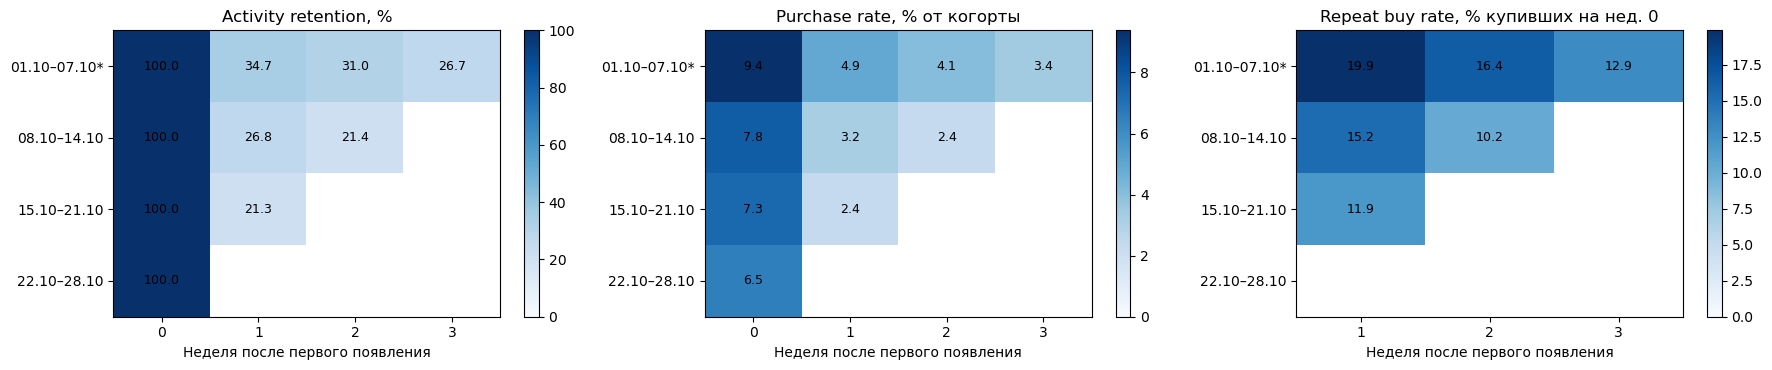

**Сводка по когортам (цифры; сравнивать когорты между собой нельзя, см. выше).**
- Когорта 01.10–07.10* (размер 957 543): на неделе 1 активны 34.7%, покупают 4.9% когорты, повторно купили 19.9% купивших на неделе 0.
- Когорта 08.10–14.10 (размер 731 325): на неделе 1 активны 26.8%, покупают 3.2% когорты, повторно купили 15.2% купивших на неделе 0.
- Когорта 15.10–21.10 (размер 623 332): на неделе 1 активны 21.3%, покупают 2.4% когорты, повторно купили 11.9% купивших на неделе 0.
- Горизонт наблюдения: до 3 нед. после недели первого появления (у последней когорты только неделя 0), данные за один месяц.

In [11]:
c = q("14_cohorts", last_full_week=LAST_FULL_WEEK)

base = c[c.week_n == 0].set_index("cohort")
c["cohort_size"]   = c["cohort"].map(base["active_users"])
c["buyers_week0"]  = c["cohort"].map(base["purchasing_users"])
c["cohort_start"]  = pd.Timestamp("2019-10-01") + pd.to_timedelta(7 * c["cohort"], unit="D")
c["cohort_label"]  = c["cohort_start"].dt.strftime("%d.%m") + "–" + (c["cohort_start"] + pd.Timedelta(days=6)).dt.strftime("%d.%m")
c.loc[c["cohort"] == 0, "cohort_label"] += "*"        # * = смешанная когорта (нет данных за сентябрь)
c["activity_retention_pct"] = (100 * c["active_users"] / c["cohort_size"]).round(2)
c["purchase_rate_pct"]      = (100 * c["purchasing_users"] / c["cohort_size"]).round(2)
c["repeat_buy_rate_pct"]    = (100 * c["repeat_buyers"] / c["buyers_week0"]).where(c["week_n"] > 0).round(2)
c["purchase_rate_of_active_pct"] = (100 * c["purchasing_users"] / c["active_users"]).round(2)
cohort_retention = c[["cohort", "cohort_label", "cohort_start", "week_n", "cohort_size", "active_users",
                      "purchasing_users", "buyers_week0", "repeat_buyers",
                      "activity_retention_pct", "purchase_rate_pct", "purchase_rate_of_active_pct", "repeat_buy_rate_pct"]]

order = list(cohort_retention.drop_duplicates("cohort")["cohort_label"])
tbl = lambda col: cohort_retention.pivot(index="cohort_label", columns="week_n", values=col).reindex(order)
act, pur, rpt = tbl("activity_retention_pct"), tbl("purchase_rate_pct"), tbl("repeat_buy_rate_pct")
pua = tbl("purchase_rate_of_active_pct")
sizes = cohort_retention[cohort_retention.week_n == 0].set_index("cohort_label")["cohort_size"].reindex(order)

print("Размеры когорт (* — смешанная когорта):"); display(sizes.to_frame("cohort_size"))
print("Activity retention, %"); display(act)
print("Purchase rate, % от когорты"); display(pur)
print("Repeat buy rate, % от купивших на неделе 0"); display(rpt)
print("Purchase rate среди активных на неделе, % (покупатели / активные)"); display(pua)

def heat(ax, df, title):
    im = ax.imshow(df.values.astype(float), cmap="Blues", aspect="auto", vmin=0)
    ax.set_xticks(range(df.shape[1])); ax.set_xticklabels(df.columns)
    ax.set_yticks(range(df.shape[0])); ax.set_yticklabels(df.index)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            v = df.iat[i, j]
            if pd.notna(v): ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9)
    ax.set_xlabel("Неделя после первого появления"); ax.set_title(title)
    plt.colorbar(im, ax=ax)

fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
heat(axes[0], act, "Activity retention, %")
heat(axes[1], pur, "Purchase rate, % от когорты")
heat(axes[2], rpt.dropna(axis=1, how="all"), "Repeat buy rate, % купивших на нед. 0")
plt.tight_layout(); plt.show()

lines = []
for lab in order:
    if 1 in act.columns and pd.notna(act.loc[lab, 1]):
        rr = rpt.loc[lab, 1] if 1 in rpt.columns else float("nan")
        lines.append(f"- Когорта {lab} (размер {n(sizes[lab])}): на неделе 1 активны {pct(act.loc[lab,1])}, "
                     f"покупают {pct(pur.loc[lab,1])} когорты, повторно купили {pct(rr)} купивших на неделе 0.")
show("**Сводка по когортам (цифры; сравнивать когорты между собой нельзя, см. выше).**\n" + "\n".join(lines) +
     f"\n- Горизонт наблюдения: до {int(cohort_retention.week_n.max())} нед. после недели первого появления (у последней когорты только неделя 0), данные за один месяц.")

**Вывод по когортам.** Что можно утверждать: на неделе 1 после первого появления возвращаются от 21% до 35% когорты, покупают 2.4–4.9% (в неделю первого появления — 6.5–9.4%). Падение покупок от недели 0 к неделе 1 объясняется в основном тем, что большинство пользователей не возвращается (65–79%), а не тем, что вернувшиеся покупают реже: доля купивших среди активных на неделе 1 выше (11–14%), чем на неделе 0 (6.5–9.4%). Оговорка: вернувшиеся — более заинтересованная группа, поэтому это не доказывает, что возврат вызывает покупки.

Чего утверждать нельзя: что удержание «ухудшается» от когорты к когорте. Снижение с 34.7% до 26.8% и 21.3% согласуется с эффектом состава когорт (давние активные пользователи сидят в первой когорте), и по данным за один месяц отделить его от реального ухудшения невозможно. Для вывода о тренде нужны данные хотя бы за 2–3 месяца.

## 7. Выгрузка агрегатов для Power BI

Сырые 42 млн строк в BI не нужны. Выгружаем небольшие таблицы, которые покрывают страницы дашборда: обзор и KPI, воронка (общая, категории, цена, бренд, время до покупки), когорты, качество данных и корзина.

In [12]:
os.makedirs("export", exist_ok=True)

kpi_overview = pd.DataFrame([{
    "period_start": raw.first_event.date(), "period_end": raw.last_event.date(),
    "total_events": int(raw.rows_cnt), "rows_after_cleaning": rows_clean,
    "all_users": all_users, "viewers": viewers, "buyers_all": buyers_all,
    "viewer_buyers": viewer_buyers, "buyers_without_view": int(users_f.buyers_without_view),
    "buyers_share_of_all_users_pct": round(buyers_share_all, 2),
    "conv_view_to_purchase_pct": round(conv_view_purchase, 2),
    "session_conv_pct": round(session_conv, 2),
    "purchase_events": int(money.purchase_events), "approx_orders": int(money.approx_orders),
    "revenue": round(revenue, 2), "revenue_per_buyer": round(revenue_per_buyer, 2),
    "avg_check_approx": round(avg_check_approx, 2),
    "repeat_buyers": int(rep.repeat_buyers), "repeat_buyers_pct": round(repeat_pct, 2),
    "cart_threshold_per_100_views": CART_THRESHOLD,
}])

daily_export = daily.copy()
daily_export["day"] = daily_export["day"].dt.date
for col in ["carts_per_100_views", "purchases_per_100_views", "purchases_per_cart", "buyers_share_pct", "avg_check_approx", "revenue"]:
    daily_export[col] = daily_export[col].round(3)

cohort_export = cohort_retention.copy()
cohort_export["cohort_start"] = cohort_export["cohort_start"].dt.date
cohort_export["is_mixed_cohort"] = cohort_export["cohort"] == 0

files = {
    "kpi_overview.csv": kpi_overview,
    "daily_metrics.csv": daily_export,
    "funnel_overall.csv": funnel_overall,
    "funnel_by_category.csv": cat,
    "funnel_by_price_band.csv": pb,
    "funnel_by_brand.csv": brand_named[brand_named["viewers"] >= MIN_VIEWERS],
    "time_to_purchase.csv": ttp,
    "cohort_retention.csv": cohort_export,
    "data_quality.csv": dq_summary,
    "cart_buyer_segments.csv": cart_buyer_segments,
    "cart_buyers_without_cart_by_day.csv": nc.assign(day=nc["day"].dt.date),
}
for name, df in files.items():
    df.to_csv(f"export/{name}", index=False, encoding="utf-8-sig")

show("**Сводка.** Сохранено в `export/`:\n" + "\n".join(f"- `{k}`: {len(v)} строк, {v.shape[1]} столбцов" for k, v in files.items()))

**Сводка.** Сохранено в `export/`:
- `kpi_overview.csv`: 1 строк, 20 столбцов
- `daily_metrics.csv`: 31 строк, 15 столбцов
- `funnel_overall.csv`: 2 строк, 4 столбцов
- `funnel_by_category.csv`: 14 строк, 9 столбцов
- `funnel_by_price_band.csv`: 5 строк, 5 столбцов
- `funnel_by_brand.csv`: 167 строк, 5 столбцов
- `time_to_purchase.csv`: 4 строк, 3 столбцов
- `cohort_retention.csv`: 10 строк, 14 столбцов
- `data_quality.csv`: 5 строк, 6 столбцов
- `cart_buyer_segments.csv`: 3 строк, 3 столбцов
- `cart_buyers_without_cart_by_day.csv`: 31 строк, 5 столбцов

## 8. Итоги, рекомендации и ограничения

*Цифры ниже зафиксированы на данных за октябрь 2019; если пересчитаете на другой выборке, обновите их вручную.*

### Что найдено
1. **Данные в целом чистые**: удалено 30 222 строки (0.07%). Главная проблема — пропуски: 32% событий без категории и 14% без бренда, из-за чего половина зрителей попадает в группу «не указана» и категорийные выводы по ним невозможны.
2. **Корзине доверять нельзя**: 41.6% покупателей не имели корзины, у 10% она появилась только после покупки, число корзин на 100 просмотров колеблется в 2.4 раза (1.34–3.28), а доля покупателей без корзины скачкообразно меняется на границах режимов (около 42% и 63%); гипотеза о корзинах из сентября не подтвердилась. Основная воронка построена без шага `cart`.
3. **Воронка**: 11.48% смотревших купили в течение месяца (6.79% по сессиям). Выручка на покупателя 662, примерный средний чек 365, 26.1% покупателей покупали минимум в два разных дня (приближение к повторным покупкам, см. определения).
4. **Выручка сосредоточена в одной категории**: electronics — 55.7% зрителей и около 77% выручки при конверсии 11.9%. Среди категорий с аудиторией от 10 000 самая низкая конверсия у apparel (2.0%), sport (2.1%) и accessories (2.2%); у apparel выручка около 0.6 млн.
5. **Главная потеря — отсутствие возврата**: на неделе 1 не возвращаются 65–79% когорты, а вернувшиеся покупают не реже (11–14% активных на неделе против 6.5–9.4% в неделю первого появления). Тренд удержания между когортами по этим данным оценить нельзя (см. раздел 6).
6. **Выручка сконцентрирована по брендам**: apple даёт около 48%, samsung около 20%. Низкая конверсия у брендов, среди которых по названиям преобладают одежда и обувь; одной ценой она, по-видимому, не объясняется (гипотеза, категории брендов не проверялись).
7. **Время до покупки**: среди купивших после просмотра около половины покупают в течение часа после первого просмотра, но около четверти — позже чем через неделю.

### Рекомендации
- **Мониторить electronics в первую очередь.** Одна категория даёт около 77% выручки, поэтому изменения в её наличии, ценах и ассортименте влияют на результат магазина сильнее всего остального. Любые KPI стоит показывать отдельно по этой категории и по остальным.
- **Оценить зависимость от двух брендов.** Около 68% выручки дают apple и samsung: изменения в их наличии, ценах и условиях поставки влияют на результат магазина так же сильно. KPI стоит показывать отдельно по этим брендам и по остальным.
- **Не считать низкую конверсию одежды и спорта приоритетной проблемой.** Она ниже, чем в любом ценовом диапазоне, и по названиям брендов связана в основном с одеждой и обувью, а вклад категорий в выручку мал (apparel 0.3%, sport 0.1%). Приоритет низкий, пока не показано, что это не особенность спроса (просмотры без намерения купить).
- **Не использовать `cart` в KPI**, пока команда не ответит, что менялось в записи корзины и её интерфейсе 4, 7, 14 и 28 октября (границы режимов) и есть ли сценарий покупки без корзины. До этого воронка остаётся двухшаговой.
- **Гипотеза для теста: возвращать пользователей после первого визита.** Большинство не возвращается на неделе 1, поэтому имеет смысл тестировать напоминания и подборки в первую неделю после визита, в том числе для тех, кто не купил. Это гипотеза: причинно-следственную связь данные не показывают.
- **Гипотезы для теста по времени до покупки.** Около половины покупок происходит в первый час, значит, влиять на них можно внутри сессии (поиск, карточка товара, оформление). Около четверти покупают позже чем через неделю: для них уместны напоминания и ремаркетинг. Это гипотезы: причинно-следственную связь данные не показывают.
- **Для оценки удержания** нужны данные минимум за 2–3 месяца, чтобы отделить новых пользователей от давних.

### Ограничения
- Один месяц данных: нет сезонности, короткие когорты, первая когорта смешанная (нет сентября), а новые пользователи позже могут оказаться давними.
- 32% событий без категории и 14% без бренда: категорийные и брендовые выводы по ним невозможны.
- Категория берётся верхнего уровня (например, electronics), внутри неё разные товары: покупка другого товара той же категории засчитывается как конверсия, поэтому категорийная конверсия выше, чем была бы по конкретным товарам.
- Категории брендов в анализе не проверялись; вывод про одежду и обувь сделан по названиям брендов и остаётся гипотезой.
- Конверсия считается по пользователям за месяц, а не по сессиям; средний чек приблизительный (нет идентификатора заказа, заказ приравнен к сессии с покупкой). Повторными считаются покупки в разные дни, несколько заказов в один день не учитываются. Валюта в данных не указана.
- Фильтрация ботов и аномально активных пользователей не проводилась: они могут слегка завышать просмотры и занижать конверсию.
- Время событий в UTC, как в источнике; границы дней и недель определены по нему, а не по местному времени магазина.
- Время до покупки считается от первого просмотра в октябре; у пришедших в конце месяца окно наблюдения короче.
- Воронка охватывает весь октябрь, когорты — только 1–28 октября (полные недели).
- Причина нестабильности корзины по данным не установлена.
- Анализ описательный: рекомендации — гипотезы для проверки (например, A/B-тестом), а не доказанные причинно-следственные связи.